# Pollution along the growth path, with NO₂

Step 2 of the pollution follow-up (`docs/successors/pollution-no2-prespec.md`, confirmed 2026-10-30): surface NO₂ (Anenberg et al. 2022) as a second outcome, on DOSE output (main arm, 2005–2018) and on night lights per person (check arm, 2005–2012). Descriptive only.

This notebook first runs the coverage gate ◇ G3. **G3 aggregates no NO₂ value:** it counts each region's valid 1 km NO₂ land cells (non-missing, at most 100 ppb).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../..'))
os.chdir(os.path.abspath('../..'))
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import src.analysis.pollution_no2 as pn
counts = pn.region_no2_counts()
print(counts.GID_1.nunique(), 'regions,', counts.year.min(), '-', counts.year.max())
cells = pn.build_no2_counts()
print('1 km land cells above 100 ppb (set missing), by year:', cells.groupby('year').n_high.sum().to_dict())
print('valid 1 km land cells, by year (millions):', (cells.groupby('year').n_valid.sum() / 1e6).round(1).to_dict())

3308 regions, 2005 - 2020


1 km land cells above 100 ppb (set missing), by year: {2005: 374, 2006: 407, 2007: 385, 2008: 353, 2009: 332, 2010: 206, 2011: 0, 2012: 139, 2013: 290, 2014: 270, 2015: 349, 2016: 341, 2017: 323, 2018: 348, 2019: 334, 2020: 197}


valid 1 km land cells, by year (millions): {2005: 116.3, 2006: 116.3, 2007: 116.2, 2008: 116.2, 2009: 116.2, 2010: 116.2, 2011: 116.3, 2012: 116.3, 2013: 116.2, 2014: 116.2, 2015: 116.2, 2016: 116.2, 2017: 116.2, 2018: 116.2, 2019: 116.3, 2020: 116.3}


## ◇ G3, DOSE arm (main): idea B's sample, 2005–2018

In [2]:
dk, dd = pn.dose_arm(counts)
print('sample:', len(dk), 'region-years,', dk.GID_1.nunique(), 'regions,', dk.GID_0.nunique(), 'countries')
print('dropped by the NO2 cell rule (< 500 valid cells):', len(dd), 'region-years in', dd.GID_1.nunique(), 'regions;',
      'by country:', dd.groupby('GID_0').GID_1.nunique().sort_values(ascending=False).head(10).to_dict())
gd = pn.g3(dk)
print(gd['by_tercile'], '\n')
n = gd['regions'].copy(); n.columns = pn.P.SEGMENT_LABELS; print(n, '\n')
print('comparisons:', gd['comparisons'])
print('G3 passes (DOSE arm):', gd['passes'])

sample: 18841 region-years, 1507 regions, 76 countries
dropped by the NO2 cell rule (< 500 valid cells): 452 region-years in 37 regions; by country: {'CHE': 7, 'IND': 2, 'KOR': 2, 'MYS': 2, 'KGZ': 2, 'NOR': 2, 'ARG': 1, 'BEL': 1, 'CAN': 1, 'ARE': 1}
         countries  regions  passes
tercile                            
0.0             26      542    True
1.0             24      569    True
2.0             26      396    True 

         < 1,000  1,000-4,000  4,000-12,000  > 12,000
tercile                                              
0.0          116          392           210        40
1.0           34          258           317       147
2.0            0           10           117       325 

comparisons: [('seg1', 0, 1), ('seg2', 0, 1), ('seg2', 1, 2), ('seg3', 1, 2)]
G3 passes (DOSE arm): True


## ◇ G3, lights arm (check): step 1's sample, knots and terciles, 2005–2012

In [3]:
lk, ld, knots = pn.lights_arm(counts)
print('knots (step 1, reproduced):', knots.round(3))
print('sample:', len(lk), 'region-years,', lk.GID_1.nunique(), 'regions,', lk.GID_0.nunique(), 'countries')
print('dropped by the NO2 cell rule:', len(ld), 'region-years in', ld.GID_1.nunique(), 'regions;',
      'by country:', ld.groupby('GID_0').GID_1.nunique().sort_values(ascending=False).head(10).to_dict())
gl = pn.g3(lk)
print(gl['by_tercile'], '\n')
n = gl['regions'].copy(); n.columns = pn.P.SEGMENT_LABELS; print(n, '\n')
print('comparisons:', gl['comparisons'])
print('G3 passes (lights arm):', gl['passes'])
h = lk[(lk.tercile == 2) & (lk.segment == 0)]
print('high tercile below 1,000 USD, regions by country:', h.groupby('GID_0').GID_1.nunique().sort_values(ascending=False).to_dict())

knots (step 1, reproduced): [-4.017 -3.02  -2.231]
sample: 21858 region-years, 2772 regions, 164 countries
dropped by the NO2 cell rule: 428 region-years in 56 regions; by country: {'CPV': 7, 'MUS': 5, 'TTO': 3, 'MNE': 3, 'PHL': 3, 'BHR': 2, 'STP': 2, 'IND': 2, 'COM': 2, 'NZL': 2}
         countries  regions  passes
tercile                            
0.0             55      802    True
1.0             54     1172    True
2.0             55      798    True 

         < 1,000  1,000-4,000  4,000-12,000  > 12,000
tercile                                              
0.0          461          204           161       144
1.0          596          419           417       205
2.0           73          164           302       457 

comparisons: [('seg0', 0, 1), ('seg0', 1, 2), ('seg1', 0, 1), ('seg1', 1, 2), ('seg2', 0, 1), ('seg2', 1, 2), ('seg3', 0, 1), ('seg3', 1, 2)]
G3 passes (lights arm): True
high tercile below 1,000 USD, regions by country: {'IND': 21, 'SEN': 14, 'MNG': 12, 'DOM': 7,

## NO₂ along the growth path: the first NO₂ load

Construction details are fixed in the change log (2026-11-04, before any NO₂ regression). Region NO₂ is the mean of the valid land 1 km cells (≤ 100 ppb) over the region's 10 km panel cells; variant 4 weights each 1 km cell by its GHS-POP density. Both arms also fit ln PM2.5 on the same rows (information, and for ◇ T1 and ◇ R1).

In [4]:
import src.analysis.pollution as P
no2 = pn.region_no2()
D = pn.dose_sample(counts, no2)
L, knots = pn.lights_sample(counts, no2)
for name, x in (('DOSE arm', D), ('lights arm', L)):
    print(f'{name}: {len(x)} region-years, {x.GID_1.nunique()} regions, {x.GID_0.nunique()} countries;',
          'NO2 ppb median', round(x.no2.median(), 2), '| 1st-99th pct', x.no2.quantile([.01, .99]).round(2).tolist())
print('lights arm knots:', knots.round(3))

DOSE arm: 18841 region-years, 1507 regions, 76 countries; NO2 ppb median 2.81 | 1st-99th pct [0.42, 11.48]
lights arm: 21858 region-years, 2772 regions, 164 countries; NO2 ppb median 2.03 | 1st-99th pct [0.17, 10.73]
lights arm knots: [-4.017 -3.02  -2.231]


## DOSE arm (main): 2005–2018, region FE + tercile × year FE, `P_a` and `T_a`

Slopes are elasticities of NO₂ with respect to output per person; country clusters.

In [5]:
dm = P.fit_paths(D, y='log_no2')
dp = P.fit_paths(D, y='log_pm25')
print('N =', dm['n'], '| NO2 joint test:', {k: float(f'{v:.3g}') for k, v in dm['wald'].items()},
      '| PM2.5 on the same rows (information):', {k: float(f'{v:.3g}') for k, v in dp['wald'].items()})
pd.concat({'NO2': dm['slopes'].set_index(['segment', 'group']), 'PM2.5': dp['slopes'].set_index(['segment', 'group'])[['est', 'se', 'p']]}, axis=1).round(4)

N = 18841 | NO2 joint test: {'F': 8.08, 'q': 4.0, 'df2': 75.0, 'p': 1.8e-05} | PM2.5 on the same rows (information): {'F': 0.225, 'q': 4.0, 'df2': 75.0, 'p': 0.923}


NO2                                     PM2.5          \
                   regions supported     est      se       p     est      se   
segment      group                                                             
< 1,000      0         116      True -0.0068  0.0414  0.8696 -0.0190  0.0380   
             1          34     False  0.3398  0.0965  0.0007  0.4357  0.1681   
             2           0     False     NaN     NaN     NaN     NaN     NaN   
1,000-4,000  0         392      True  0.1048  0.0570  0.0699  0.0459  0.0304   
             1         258      True  0.1365  0.0328  0.0001  0.0245  0.0696   
             2          10     False  0.4497  0.0679  0.0000  0.2090  0.0674   
4,000-12,000 0         210      True -0.0088  0.0333  0.7920 -0.0245  0.0440   
             1         317      True  0.1327  0.0690  0.0582 -0.0027  0.0862   
             2         117      True  0.3447  0.0561  0.0000  0.0288  0.0524   
> 12,000     0          40     False -0.0697  0.0722  0.3378 -0.0604  0.0358   
             1         147      True -0.0595  0.0425  0.1658 -0.0086  0.0380   
             2         325      True  0.0937  0.0671  0.1667  0.0190  0.0395   

                            
                         p  
segment      group          
< 1,000      0      0.6185  
             1      0.0115  
             2         NaN  
1,000-4,000  0      0.1352  
             1      0.7262  
             2      0.0027  
4,000-12,000 0      0.5794  
             1      0.9747  
             2      0.5837  
> 12,000     0      0.0956  
             1      0.8212  
             2      0.6319

In [6]:
pd.concat({'NO2': dm['diffs'].set_index(['segment', 'comparison']), 'PM2.5': dp['diffs'].set_index(['segment', 'comparison'])}, axis=1).round(4)

NO2                   PM2.5                
                           diff      se       p    diff      se       p
segment      comparison                                                
1,000-4,000  1 - 0       0.0317  0.0654  0.6297 -0.0215  0.0762  0.7786
4,000-12,000 1 - 0       0.1415  0.0767  0.0690  0.0217  0.0966  0.8226
             2 - 1       0.2120  0.0891  0.0199  0.0316  0.1017  0.7573
> 12,000     2 - 1       0.1532  0.0791  0.0565  0.0276  0.0550  0.6167

In [7]:
d1, tr = P.add_country_trends(D)
DV = {'1 + country trends': P.fit_paths(d1, y='log_no2', extra=tr),
      '2 country x year FE': P.fit_paths(D, y='log_no2', fe='GID_1 + GID_0^year'),
      '3 rule of law': P.fit_paths(D, group='tercile_rule', y='log_no2'),
      '4 pop-weighted NO2 + pop weights': P.fit_paths(D[D.log_no2_popw.notna()], y='log_no2_popw', weights='pop'),
      '5 NO2 in levels (ppb)': P.fit_paths(D, y='no2')}
dpool = P.fit_pooled(D, y='log_no2')
print('pooled NO2 path (region + year FE):'); print(dpool['slopes'].round(4))

pooled NO2 path (region + year FE):
              Estimate  Std. Error  Pr(>|t|)
< 1,000         0.1216      0.0558    0.0324
1,000-4,000     0.1917      0.0422    0.0000
4,000-12,000    0.1442      0.0497    0.0049
> 12,000       -0.0424      0.0369    0.2532


## Lights arm (check): 2005–2012, step 1's knots and terciles, region FE + tercile × year FE, no weather

Variant H uses step 1's low-haze regions; variants 6 and 7 use step 1's knots for those variants (change log, 2026-11-04).

In [8]:
lm = P.fit_paths(L, y='log_no2', controls=())
lp = P.fit_paths(L, y='log_pm25', controls=())
print('N =', lm['n'], '| NO2 joint test:', {k: float(f'{v:.3g}') for k, v in lm['wald'].items()},
      '| PM2.5 on the same rows (information):', {k: float(f'{v:.3g}') for k, v in lp['wald'].items()})
pd.concat({'NO2': lm['slopes'].set_index(['segment', 'group']), 'PM2.5': lp['slopes'].set_index(['segment', 'group'])[['est', 'se', 'p']]}, axis=1).round(4)

N = 21846 | NO2 joint test: {'F': 2.13, 'q': 8.0, 'df2': 163.0, 'p': 0.0362} | PM2.5 on the same rows (information): {'F': 2.67, 'q': 8.0, 'df2': 163.0, 'p': 0.00882}


NO2                                     PM2.5          \
                   regions supported     est      se       p     est      se   
segment      group                                                             
< 1,000      0         461      True -0.0095  0.0075  0.2067  0.0113  0.0090   
             1         596      True -0.0005  0.0061  0.9300  0.0015  0.0142   
             2          73      True  0.0532  0.0235  0.0253  0.0326  0.0230   
1,000-4,000  0         204      True  0.0503  0.0465  0.2808 -0.0941  0.0294   
             1         419      True  0.0265  0.0124  0.0340  0.0424  0.0236   
             2         164      True  0.1059  0.0454  0.0207  0.0512  0.0552   
4,000-12,000 0         161      True -0.0304  0.0360  0.3986 -0.0948  0.0419   
             1         417      True  0.0395  0.0174  0.0242  0.0086  0.0334   
             2         302      True  0.1207  0.0394  0.0026 -0.0310  0.0396   
> 12,000     0         144      True -0.0329  0.0235  0.1632  0.0664  0.0704   
             1         205      True -0.0648  0.0292  0.0278 -0.0407  0.0283   
             2         457      True  0.0303  0.0266  0.2559  0.0501  0.0395   

                            
                         p  
segment      group          
< 1,000      0      0.2118  
             1      0.9144  
             2      0.1577  
1,000-4,000  0      0.0017  
             1      0.0745  
             2      0.3548  
4,000-12,000 0      0.0249  
             1      0.7976  
             2      0.4340  
> 12,000     0      0.3474  
             1      0.1524  
             2      0.2066

In [9]:
pd.concat({'NO2': lm['diffs'].set_index(['segment', 'comparison']), 'PM2.5': lp['diffs'].set_index(['segment', 'comparison'])}, axis=1).round(4)

NO2                   PM2.5                
                           diff      se       p    diff      se       p
segment      comparison                                                
< 1,000      1 - 0       0.0090  0.0097  0.3560 -0.0098  0.0168  0.5620
             2 - 1       0.0537  0.0243  0.0287  0.0311  0.0270  0.2516
1,000-4,000  1 - 0      -0.0238  0.0481  0.6211  0.1365  0.0377  0.0004
             2 - 1       0.0795  0.0470  0.0929  0.0088  0.0600  0.8835
4,000-12,000 1 - 0       0.0699  0.0399  0.0817  0.1034  0.0536  0.0554
             2 - 1       0.0812  0.0431  0.0612 -0.0396  0.0518  0.4453
> 12,000     1 - 0      -0.0319  0.0375  0.3967 -0.1071  0.0759  0.1603
             2 - 1       0.0951  0.0395  0.0171  0.0908  0.0486  0.0635

In [10]:
import src.analysis.pollution_lights as pl
s1 = pl.sample(pl.build_lights_panel())
k7 = pl.calibrate_knots(s1, x='log_lpa')['knots']
LH = L[L.GID_1.isin(pn.low_haze_regions())]
l1, trl = P.add_country_trends(L)
L6 = pn.viirs_sample(counts, no2)
L8 = L[L.glass_ta.notna()]
print('H:', len(LH), 'region-years,', LH.GID_1.nunique(), 'regions | 6:', len(L6), 'region-years,', L6.GID_0.nunique(),
      'countries | 8:', len(L8), 'region-years')
LV = {'1 + country trends': P.fit_paths(l1, y='log_no2', controls=(), extra=trl),
      '2 country x year FE': P.fit_paths(L, y='log_no2', controls=(), fe='GID_1 + GID_0^year'),
      'H low haze': P.fit_paths(LH, y='log_no2', controls=()),
      '3 rule of law': P.fit_paths(L, group='tercile_rule', y='log_no2', controls=()),
      '4 pop-weighted NO2 + pop weights': P.fit_paths(L[L.log_no2_popw.notna()], y='log_no2_popw', weights='pop', controls=()),
      '5 NO2 in levels (ppb)': P.fit_paths(L, y='no2', controls=()),
      '6 VIIRS years 2014-2020': P.fit_paths(L6, y='log_no2', controls=()),
      '7 lights per area': P.fit_paths(pn.respline(L, k7, 'log_lpa'), y='log_no2', controls=()),
      '8 + GLASS air temperature': P.fit_paths(L8, y='log_no2', controls=('glass_ta',))}
lpool = P.fit_pooled(L, y='log_no2', controls=())
print('pooled NO2 path (region + year FE):'); print(lpool['slopes'].round(4))

H: 14402 region-years, 1813 regions | 6: 19458 region-years, 164 countries | 8: 21858 region-years


pooled NO2 path (region + year FE):
              Estimate  Std. Error  Pr(>|t|)
< 1,000         0.0062      0.0047    0.1900
1,000-4,000     0.0413      0.0165    0.0136
4,000-12,000    0.0246      0.0171    0.1516
> 12,000       -0.0388      0.0205    0.0598


## ◇ T1, transport: stacked NO₂ and PM2.5 pooled paths, region + country × year FE

Per segment: the NO₂ and PM2.5 slopes, NO₂ − PM2.5 with a one-sided p (> 0), Holm-adjusted across the four segments, and the two-sided p (information).

In [11]:
sd = pn.fit_stacked(D, controls=pn.WEATHER)
sl = pn.fit_stacked(L)
for name, r in (('DOSE arm', sd), ('lights arm', sl)):
    print(name, '| N (stacked) =', r['n']); print(r['table'].round(4).to_string(index=False), '\n')
T1 = pn.t1(sd, sl)
print('T1:', 'NO2 has a within-country path that PM2.5 lacks' if T1['claim'] else
      'NO2 does not show a within-country path that PM2.5 lacks', T1['segments'])

DOSE arm | N (stacked) = 37644
     segment     no2  p_no2    pm25    diff     se  p_one  p_two  p_holm
     < 1,000  0.0413 0.0400 -0.0047  0.0461 0.0407 0.1307 0.2614  0.2614
 1,000-4,000  0.0680 0.0033 -0.0229  0.0910 0.0275 0.0007 0.0014  0.0029
4,000-12,000  0.0213 0.2475 -0.0278  0.0492 0.0242 0.0231 0.0461  0.0692
    > 12,000 -0.0168 0.5060  0.0107 -0.0275 0.0259 0.8543 0.2913  0.8543 

lights arm | N (stacked) = 43628
     segment     no2  p_no2    pm25    diff     se  p_one  p_two  p_holm
     < 1,000  0.0024 0.4511  0.0054 -0.0030 0.0035 0.8038 0.3924     1.0
 1,000-4,000  0.0053 0.5602  0.0071 -0.0018 0.0145 0.5483 0.9034     1.0
4,000-12,000  0.0118 0.3676  0.0118  0.0000 0.0184 0.4999 0.9999     1.0
    > 12,000 -0.0167 0.2662 -0.0047 -0.0120 0.0130 0.8207 0.3585     1.0 

T1: NO2 does not show a within-country path that PM2.5 lacks []


## ◇ R1, ◇ moderation and ◇ turning point

In [12]:
R1 = pn.r1(lm)
ri = pn.r1(lp)
print('R1 (lights, NO2, > 12k, high - middle):', round(R1['diff'], 4), 'p =', round(R1['p'], 4), '->',
      "step 1's difference replicates with NO2" if R1['claim'] else 'does not replicate')
print('   PM2.5 on the NO2 rows (information):', round(ri['diff'], 4), 'p =', round(ri['p'], 4))
for name, main, checks in (('DOSE arm', dm, {k: DV[k] for k in ('1 + country trends', '2 country x year FE')}),
                           ('lights arm', lm, {k: LV[k] for k in ('1 + country trends', '2 country x year FE', 'H low haze')})):
    r = pn.moderation(main, checks)
    print(f'\n{name} MODERATION:', 'institutions change the path' if r['claim'] else 'no robust difference',
          '| Wald rejects:', r['rejects'], '| at 5 %:', len(r['significant']), '| keep sign:', r['keeps'])
    if len(r['significant']):
        print(r['significant'].round(4).to_string(index=False))
print('\nTURNING POINT, DOSE arm (negative at 5 % in main):', pn.downturns(dm))
print('TURNING POINT, lights arm (negative at 5 % in main and H):', pn.downturns(lm, LV['H low haze']))

R1 (lights, NO2, > 12k, high - middle): 0.0951 p = 0.0171 -> step 1's difference replicates with NO2
   PM2.5 on the NO2 rows (information): 0.0908 p = 0.0635

DOSE arm MODERATION: institutions change the path | Wald rejects: True | at 5 %: 1 | keep sign: True
     segment comparison  diff      p  1 + country trends  2 country x year FE
4,000-12,000      2 - 1 0.212 0.0199              0.0013               0.0216

lights arm MODERATION: no robust difference | Wald rejects: True | at 5 %: 2 | keep sign: False
 segment comparison   diff      p  1 + country trends  2 country x year FE  H low haze
 < 1,000      2 - 1 0.0537 0.0287              0.0047               0.0062         NaN
> 12,000      2 - 1 0.0951 0.0171              0.0064               0.0479      0.1045

TURNING POINT, DOSE arm (negative at 5 % in main): []
TURNING POINT, lights arm (negative at 5 % in main and H): []


### Summary across variants

For each: N, the joint test, the number of comparisons at 5 %, and the high − middle comparison above 12,000 USD (the top quartile where the knots are quartiles).

In [13]:
def row(name, r):
    dd = r['diffs'].set_index(['segment', 'comparison'])
    kk = ('> 12,000', '2 - 1')
    top = (dd.loc[kk, 'diff'], dd.loc[kk, 'p']) if kk in dd.index else (np.nan, np.nan)
    return dict(variant=name, N=r['n'], q=r['wald']['q'], wald_p=r['wald']['p'], n_sig=int((r['diffs'].p < 0.05).sum()),
                **{'high-mid >12k': top[0], 'p': top[1]})
pd.concat({'DOSE': pd.DataFrame([row(k, r) for k, r in {'main': dm, 'PM2.5 same rows': dp, **DV}.items()]).set_index('variant'),
           'lights': pd.DataFrame([row(k, r) for k, r in {'main': lm, 'PM2.5 same rows': lp, **LV}.items()]).set_index('variant')}).round(3)

N  q  wald_p  n_sig  \
       variant                                                     
DOSE   main                              18841  4   0.000      1   
       PM2.5 same rows                   18841  4   0.923      0   
       1 + country trends                18841  4   0.177      0   
       2 country x year FE               18822  4   0.283      0   
       3 rule of law                     18841  5   0.000      2   
       4 pop-weighted NO2 + pop weights  18315  4   0.000      2   
       5 NO2 in levels (ppb)             18841  4   0.000      2   
lights main                              21846  8   0.036      2   
       PM2.5 same rows                   21846  8   0.009      1   
       1 + country trends                21846  8   0.154      1   
       2 country x year FE               21814  8   0.568      0   
       H low haze                        14398  6   0.006      3   
       3 rule of law                     21846  8   0.001      4   
       4 pop-weighted NO2 + pop weights  21846  8   0.000      4   
       5 NO2 in levels (ppb)             21846  8   0.010      3   
       6 VIIRS years 2014-2020           19453  7   0.135      2   
       7 lights per area                 21846  8   0.006      2   
       8 + GLASS air temperature         21846  8   0.044      2   

                                         high-mid >12k      p  
       variant                                                 
DOSE   main                                      0.153  0.057  
       PM2.5 same rows                           0.028  0.617  
       1 + country trends                        0.059  0.106  
       2 country x year FE                       0.030  0.522  
       3 rule of law                             0.329  0.006  
       4 pop-weighted NO2 + pop weights          0.377  0.044  
       5 NO2 in levels (ppb)                     0.678  0.049  
lights main                                      0.095  0.017  
       PM2.5 same rows                           0.091  0.064  
       1 + country trends                        0.006  0.812  
       2 country x year FE                       0.048  0.090  
       H low haze                                0.104  0.022  
       3 rule of law                             0.105  0.008  
       4 pop-weighted NO2 + pop weights          0.321  0.008  
       5 NO2 in levels (ppb)                     0.414  0.003  
       6 VIIRS years 2014-2020                   0.026  0.187  
       7 lights per area                        -0.016  0.764  
       8 + GLASS air temperature                 0.095  0.022

In [14]:
with pd.option_context('display.max_rows', 300):
    display(pd.concat({f'{a} {k}': r['diffs'] for a, V in (('DOSE', DV), ('lights', LV)) for k, r in V.items()}).round(4))

segment comparison    diff  \
DOSE 1 + country trends                 0   1,000-4,000      1 - 0 -0.0574   
                                        1  4,000-12,000      1 - 0  0.0346   
                                        2  4,000-12,000      2 - 1  0.0013   
                                        3      > 12,000      2 - 1  0.0588   
DOSE 2 country x year FE                0   1,000-4,000      1 - 0 -0.0582   
                                        1  4,000-12,000      1 - 0  0.0348   
                                        2  4,000-12,000      2 - 1  0.0216   
                                        3      > 12,000      2 - 1  0.0301   
DOSE 3 rule of law                      0       < 1,000      1 - 0 -0.0067   
                                        1   1,000-4,000      1 - 0  0.0315   
                                        2  4,000-12,000      1 - 0  0.1114   
                                        3  4,000-12,000      2 - 1  0.2846   
                                        4      > 12,000      2 - 1  0.3293   
DOSE 4 pop-weighted NO2 + pop weights   0   1,000-4,000      1 - 0  0.1097   
                                        1  4,000-12,000      1 - 0  0.1903   
                                        2  4,000-12,000      2 - 1  0.5023   
                                        3      > 12,000      2 - 1  0.3774   
DOSE 5 NO2 in levels (ppb)              0   1,000-4,000      1 - 0 -0.2042   
                                        1  4,000-12,000      1 - 0  0.5201   
                                        2  4,000-12,000      2 - 1  0.9036   
                                        3      > 12,000      2 - 1  0.6777   
lights 1 + country trends               0       < 1,000      1 - 0 -0.0026   
                                        1       < 1,000      2 - 1  0.0047   
                                        2   1,000-4,000      1 - 0 -0.0032   
                                        3   1,000-4,000      2 - 1 -0.0187   
                                        4  4,000-12,000      1 - 0  0.0142   
                                        5  4,000-12,000      2 - 1 -0.0809   
                                        6      > 12,000      1 - 0 -0.0122   
                                        7      > 12,000      2 - 1  0.0064   
lights 2 country x year FE              0       < 1,000      1 - 0  0.0004   
                                        1       < 1,000      2 - 1  0.0062   
                                        2   1,000-4,000      1 - 0 -0.0111   
                                        3   1,000-4,000      2 - 1  0.0199   
                                        4  4,000-12,000      1 - 0  0.0143   
                                        5  4,000-12,000      2 - 1 -0.0427   
                                        6      > 12,000      1 - 0 -0.0095   
                                        7      > 12,000      2 - 1  0.0479   
lights H low haze                       0       < 1,000      1 - 0  0.0217   
                                        1   1,000-4,000      1 - 0 -0.0059   
                                        2   1,000-4,000      2 - 1  0.0733   
                                        3  4,000-12,000      1 - 0  0.1151   
                                        4  4,000-12,000      2 - 1  0.1254   
                                        5      > 12,000      2 - 1  0.1045   
lights 3 rule of law                    0       < 1,000      1 - 0 -0.0110   
                                        1       < 1,000      2 - 1  0.0480   
                                        2   1,000-4,000      1 - 0 -0.0166   
                                        3   1,000-4,000      2 - 1  0.0893   
                                        4  4,000-12,000      1 - 0  0.0038   
                                        5  4,000-12,000      2 - 1  0.1099   
                                        6      > 12,000      1 - 0  0.0387   
                                        7      > 12,000      2 - 1  0.

In [15]:
with pd.option_context('display.max_rows', 300):
    display(pd.concat({f'{a} {k}': r['slopes'] for a, V in (('DOSE', DV), ('lights', LV)) for k, r in V.items()}).round(4))

segment  group  regions  \
DOSE 1 + country trends                 0        < 1,000      0      116   
                                        1        < 1,000      1       34   
                                        2        < 1,000      2        0   
                                        3    1,000-4,000      0      392   
                                        4    1,000-4,000      1      258   
                                        5    1,000-4,000      2       10   
                                        6   4,000-12,000      0      210   
                                        7   4,000-12,000      1      317   
                                        8   4,000-12,000      2      117   
                                        9       > 12,000      0       40   
                                        10      > 12,000      1      147   
                                        11      > 12,000      2      325   
DOSE 2 country x year FE                0        < 1,000      0      116   
                                        1        < 1,000      1       34   
                                        2        < 1,000      2        0   
                                        3    1,000-4,000      0      392   
                                        4    1,000-4,000      1      258   
                                        5    1,000-4,000      2       10   
                                        6   4,000-12,000      0      210   
                                        7   4,000-12,000      1      317   
                                        8   4,000-12,000      2      117   
                                        9       > 12,000      0       40   
                                        10      > 12,000      1      147   
                                        11      > 12,000      2      325   
DOSE 3 rule of law                      0        < 1,000      0       83   
                                        1        < 1,000      1       67   
                                        2        < 1,000      2        0   
                                        3    1,000-4,000      0      408   
                                        4    1,000-4,000      1      252   
                                        5    1,000-4,000      2        0   
                                        6   4,000-12,000      0      220   
                                        7   4,000-12,000      1      354   
                                        8   4,000-12,000      2       70   
                                        9       > 12,000      0       36   
                                        10      > 12,000      1      118   
                                        11      > 12,000      2      358   
DOSE 4 pop-weighted NO2 + pop weights   0        < 1,000      0      116   
                                        1        < 1,000      1       34   
                                        2        < 1,000      2        0   
                                        3    1,000-4,000      0      392   
                                        4    1,000-4,000      1      258   
                                        5    1,000-4,000      2       10   
                                        6   4,000-12,000      0      210   
                                        7   4,000-12,000      1      317   
                                        8   4,000-12,000      2      117   
                                        9       > 12,000      0       40   
                                        10      > 12,000      1      147   
                                        11      > 12,000      2      325   
DOSE 5 NO2 in levels (ppb)              0        < 1,000      0      116   
                                        1        < 1,000      1       34   
                                        2        < 1,000      2        0   
                                        3    1,000-4,000      0      392   
                     

## Figure: NO₂ along the output path (DOSE arm)

**a**, Pooled path: NO₂ relative to output per person at 4,000 USD (region + year FE, `P_a`, `T_a`), with a 95 % band (country clusters). Below, the region-years. **b**, Paths by baseline democracy tercile (main specification), each over its supported segments within its 1st–99th percentile. Below, each tercile's distribution: 5–95 % (thin), interquartile range (thick), median (circle). **c**, Segment elasticities in the main specification and variants 1–2, with 95 % intervals. Descriptive only.

Saved to `output/figures/pollution/no2_paths.{pdf,png}`.

INFO:fontTools.subset:maxp pruned


INFO:fontTools.subset:cmap pruned


INFO:fontTools.subset:post pruned


INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:PCLT dropped


INFO:fontTools.subset:GPOS pruned


... (68 outputs left out)

INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:GPOS pruned


INFO:fontTools.subset:GSUB pruned


INFO:fontTools.subset:name pruned


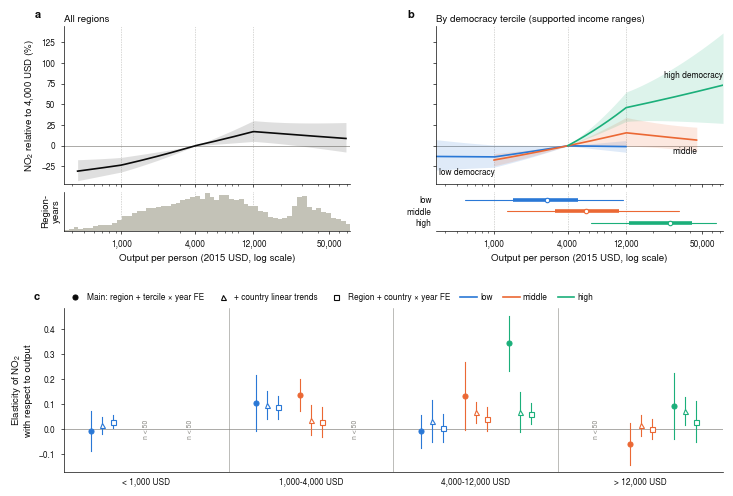

In [16]:
fig = P.plot_paths(D, dpool, dm, {'+ country trends': DV['1 + country trends'], 'country × year FE': DV['2 country x year FE']})
fig.axes[0].set_ylabel(f'NO$_2$ relative to {P.REF_USD:,} USD (%)')
fig.axes[4].set_ylabel('Elasticity of NO$_2$\nwith respect to output')
fig = P._save(fig, f'{P.FIGURES}/no2_paths')

## Figure: ◇ T1, within-country NO₂ and PM2.5

Segment elasticities from the stacked fits with region + country × year FE, 95 % intervals (country clusters). Above each segment: NO₂ − PM2.5 and its Holm-adjusted one-sided p (dark if below 0.05). **a**, DOSE arm (output per person, with `P_a` and `T_a`). **b**, lights arm (ln lights per person at step 1's knots; the segments are the same USD ranges by the DOSE calibration).

Saved to `output/figures/pollution/no2_transport.{pdf,png}`.

INFO:fontTools.subset:maxp pruned


INFO:fontTools.subset:cmap pruned


INFO:fontTools.subset:post pruned


INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:PCLT dropped


INFO:fontTools.subset:GPOS pruned


... (68 outputs left out)

INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:GPOS pruned


INFO:fontTools.subset:GSUB pruned


INFO:fontTools.subset:name pruned


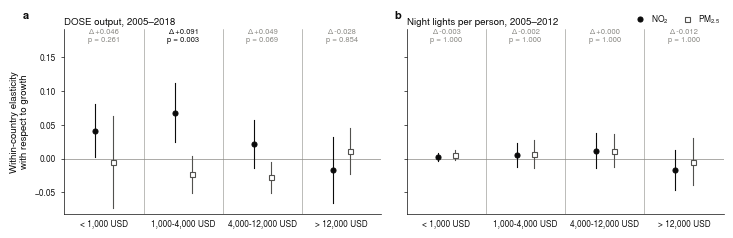

In [17]:
fig = pn.plot_transport(sd, sl, f'{P.FIGURES}/no2_transport')